# AI-Based Packet Loss Detection and Prediction System
**Computer Networks project** - network built in Cisco Packet Tracer, AI system built here in Colab.

Run the cells **in order** (Runtime -> Run all also works).

| Step | Cell | What it does |
|---|---|---|
| 1 | Setup | imports |
| 2 | Topology | 3 LANs, 3 routers, Server0, 6 monitored links |
| 3 | Data | link-level traffic simulation (or your Packet Tracer CSV) |
| 4 | EDA | congestion -> queue -> loss |
| 5 | Features | history features + future targets + time-based split |
| 6 | Detection | is loss happening **now**? |
| 7 | Prediction | will loss happen in the **next H seconds**? |
| 8 | Regression | how **much** loss in the next H seconds? |
| 9 | Unseen links | does the model generalise to links it never trained on? |
| 10 | Early warning | alert quality: warned %, lead time, false alarms |
| 11 | Inference demo | `analyze_link()` on Normal vs Pre-congestion |
| 12 | Save | models, metrics, ZIP download |

## 1. Setup

In [1]:
import os, json, shutil, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import networkx as nx, joblib
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier,
                              RandomForestRegressor, HistGradientBoostingRegressor)
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.inspection import permutation_importance
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, confusion_matrix, ConfusionMatrixDisplay,
                             mean_absolute_error, mean_squared_error, r2_score)

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
SEED = 42
rng = np.random.default_rng(SEED)
OUTPUT_DIR = 'packet_loss_project'
os.makedirs(OUTPUT_DIR, exist_ok=True)
print('AI-Based Packet Loss Detection and Prediction System - environment ready')

AI-Based Packet Loss Detection and Prediction System - environment ready


## 2. Network topology (same as the Packet Tracer design)
Six links are monitored. All three LANs send traffic to **Server0**, so the **Router1 - Server0** link is the shared bottleneck.

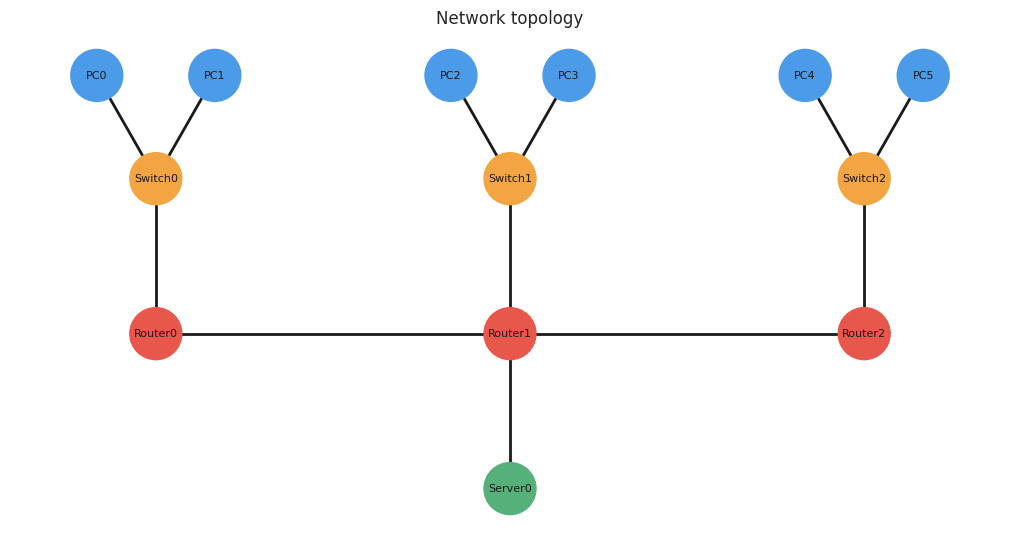

Subnets:
  LAN1 -> 192.168.10.0/24
  LAN2 -> 192.168.20.0/24
  LAN3 -> 192.168.30.0/24
  SERVER -> 192.168.40.0/24

Monitored links: ['LAN1_Router0', 'LAN2_Router1', 'LAN3_Router2', 'Router0_Router1', 'Router1_Router2', 'Router1_Server0']


In [2]:
TOPOLOGY = {
    'LAN1':   {'router': 'Router0', 'switch': 'Switch0', 'pcs': ['PC0', 'PC1'], 'subnet': '192.168.10.0/24'},
    'LAN2':   {'router': 'Router1', 'switch': 'Switch1', 'pcs': ['PC2', 'PC3'], 'subnet': '192.168.20.0/24'},
    'LAN3':   {'router': 'Router2', 'switch': 'Switch2', 'pcs': ['PC4', 'PC5'], 'subnet': '192.168.30.0/24'},
    'SERVER': {'name': 'Server0', 'router': 'Router1', 'subnet': '192.168.40.0/24'},
}

# monitored links: capacity (Mbps; inter-router links assumed slower at 40), one-way base delay (ms), type
LINKS = {
    'LAN1_Router0':    {'capacity': 100, 'base_delay': 1.5, 'type': 'LAN'},
    'LAN2_Router1':    {'capacity': 100, 'base_delay': 1.5, 'type': 'LAN'},
    'LAN3_Router2':    {'capacity': 100, 'base_delay': 1.5, 'type': 'LAN'},
    'Router0_Router1': {'capacity': 40, 'base_delay': 5.0, 'type': 'INTER_ROUTER'},
    'Router1_Router2': {'capacity': 40, 'base_delay': 5.0, 'type': 'INTER_ROUTER'},
    'Router1_Server0': {'capacity': 100, 'base_delay': 1.0, 'type': 'SERVER'},
}

G = nx.Graph()
G.add_edges_from([('PC0','Switch0'),('PC1','Switch0'),('Switch0','Router0'),
                  ('PC2','Switch1'),('PC3','Switch1'),('Switch1','Router1'),
                  ('PC4','Switch2'),('PC5','Switch2'),('Switch2','Router2'),
                  ('Router0','Router1'),('Router1','Router2'),('Router1','Server0')])
pos = {'PC0':(0,3),'PC1':(1,3),'Switch0':(0.5,2),'Router0':(0.5,0.5),
       'PC2':(3,3),'PC3':(4,3),'Switch1':(3.5,2),'Router1':(3.5,0.5),'Server0':(3.5,-1),
       'PC4':(6,3),'PC5':(7,3),'Switch2':(6.5,2),'Router2':(6.5,0.5)}
colors = ['#4C9BE8' if n.startswith('PC') else '#F2A541' if n.startswith('Switch')
          else '#E8574C' if n.startswith('Router') else '#55B07A' for n in G]
plt.figure(figsize=(10,5))
nx.draw(G, pos, with_labels=True, node_color=colors, node_size=1400, font_size=8, width=2)
plt.title('Network topology'); plt.show()

print('Subnets:')
for k, v in TOPOLOGY.items(): print(' ', k, '->', v['subnet'])
print('\nMonitored links:', list(LINKS))

## 3. Data
**Option A (default)** - simulation built on the topology. Each LAN has a Markov traffic state (Normal / Moderate / Congested / Burst). Traffic flows through the real paths to Server0, each link has a queue that fills when load exceeds capacity, and packets are dropped (early drops when the queue is >60% full, tail drops when it overflows). So loss is *preceded* by rising load and queue - exactly what a predictor can learn.

**Option B** - your own Packet Tracer measurements. Set `USE_PT_CSV = True` and provide a CSV with one row per link per second and these columns:
`link_name, time, capacity_mbps, packet_rate_pps, packet_size_bytes, offered_load_mbps, utilization_pct, queue_length, rtt_ms, jitter_ms, throughput_mbps, retransmissions, loss_pct`
(e.g. from `ping -n 100`, interface counters from `show interfaces`, and `show policy-map` / queue statistics.)

In [3]:
USE_PT_CSV = False
PT_CSV_PATH = 'pt_measurements.csv'

N = 10000                      # seconds per link
LOSS_THRESHOLD_PCT = 2         # >= 2% loss in the 1-second probe window = loss event
SCEN_MEAN = np.array([0.15, 0.32, 0.50, 0.72])   # mean LAN load as fraction of 100 Mbps
TRANS = np.array([[0.91, 0.07, 0.01, 0.01],
                  [0.15, 0.72, 0.08, 0.05],
                  [0.04, 0.18, 0.68, 0.10],
                  [0.10, 0.15, 0.20, 0.55]])

def lan_demand(n):
    scen = np.zeros(n, dtype=int); scen[0] = rng.choice(4, p=[.55,.25,.15,.05])
    for t in range(1, n): scen[t] = rng.choice(4, p=TRANS[scen[t-1]])
    target = SCEN_MEAN[scen] * 100
    load = np.zeros(n); load[0] = target[0]
    for t in range(1, n):
        load[t] = 0.8*load[t-1] + 0.2*target[t] + rng.normal(0, 3)
        if scen[t] == 3 and rng.random() < 0.08: load[t] *= 1.5       # micro-bursts
    return np.clip(load, 2, None), scen

def simulate_link(name, load, scen, cfg):
    n, cap = len(load), cfg['capacity']
    q = np.zeros(n); p = np.zeros(n); qq = 0.0
    for t in range(n):
        L = load[t]
        qq = float(np.clip(qq + (L - cap)/cap*0.5, 0, 1))              # fluid queue (0..1 = empty..full)
        early = 0.15 * max(0.0, (qq - 0.6)/0.4)**2                      # early drop (RED-like)
        over = max(0.0, (L - cap)/L) if qq >= 0.999 else 0.0            # tail drop
        q[t] = qq; p[t] = min(0.9, early + over + 0.0005)
    size = np.clip(rng.normal(800, 150, n), 64, 1500)
    pps = load*1e6/8/size
    rtt = 2*cfg['base_delay'] + q*30 + rng.exponential(0.3, n)
    jitter = 0.2 + np.abs(np.diff(rtt, prepend=rtt[0]))*0.6 + rng.exponential(0.1, n)
    return pd.DataFrame({
        'link_name': name, 'time': np.arange(n), 'capacity_mbps': cap,
        'packet_rate_pps': pps, 'packet_size_bytes': size, 'offered_load_mbps': load,
        'utilization_pct': np.clip(load/cap*100 + rng.normal(0, 1.5, n), 0, 100),
        'queue_length': np.clip(q*64 + rng.normal(0, 1.5, n), 0, None),
        'rtt_ms': rtt, 'jitter_ms': jitter,
        'throughput_mbps': np.minimum(load, cap)*(1 - p),
        'retransmissions': rng.poisson(0.3 + pps*p*0.004),
        'loss_pct': rng.binomial(100, p).astype(float),
        'traffic_scenario': scen})

if USE_PT_CSV:
    df = pd.read_csv(PT_CSV_PATH)
else:
    d = {k: lan_demand(N) for k in ['LAN1', 'LAN2', 'LAN3']}
    l = {k: v[0] for k, v in d.items()}; s = {k: v[1] for k, v in d.items()}
    link_load = {'LAN1_Router0': l['LAN1'], 'Router0_Router1': l['LAN1'],
                 'LAN2_Router1': l['LAN2'],
                 'LAN3_Router2': l['LAN3'], 'Router1_Router2': l['LAN3'],
                 'Router1_Server0': l['LAN1'] + l['LAN2'] + l['LAN3']}
    link_scen = {'LAN1_Router0': s['LAN1'], 'Router0_Router1': s['LAN1'], 'LAN2_Router1': s['LAN2'],
                 'LAN3_Router2': s['LAN3'], 'Router1_Router2': s['LAN3'],
                 'Router1_Server0': np.maximum.reduce([s['LAN1'], s['LAN2'], s['LAN3']])}
    df = pd.concat([simulate_link(nm, link_load[nm], link_scen[nm], cfg) for nm, cfg in LINKS.items()],
                   ignore_index=True)

df['current_loss'] = (df['loss_pct'] >= LOSS_THRESHOLD_PCT).astype(int)
print('Records:', df.shape, '| links:', df['link_name'].nunique(), '| missing values:', int(df.isnull().sum().sum()))
print('Loss-event rate: %.1f%%' % (df['current_loss'].mean()*100))
display(df.head())

Records: (60000, 15) | links: 6 | missing values: 0
Loss-event rate: 7.0%


,link_name,time,capacity_mbps,packet_rate_pps,packet_size_bytes,offered_load_mbps,utilization_pct,queue_length,rtt_ms,jitter_ms,throughput_mbps,retransmissions,loss_pct,traffic_scenario,current_loss
0,LAN1_Router0,0,100,6715.069852,595.675114,32.000000,31.797726,0.000000,3.307821,0.336665,31.984000,0,0.0,1,0
1,LAN1_Router0,1,100,5773.214238,570.523059,26.350015,25.486091,0.000000,3.572709,0.500015,26.336840,1,0.0,1,0
2,LAN1_Router0,2,100,4867.951494,792.721677,30.871445,30.475452,0.498173,3.029283,0.566903,30.856010,0,0.0,1,0
3,LAN1_Router0,3,100,5484.105168,789.676023,34.645331,34.429732,0.000000,3.437941,0.480883,34.628008,0,0.0,1,0
4,LAN1_Router0,4,100,4678.784279,782.606189,29.293164,26.893569,1.329622,3.140641,0.439729,29.278518,0,0.0,0,0


## 4. Exploratory analysis

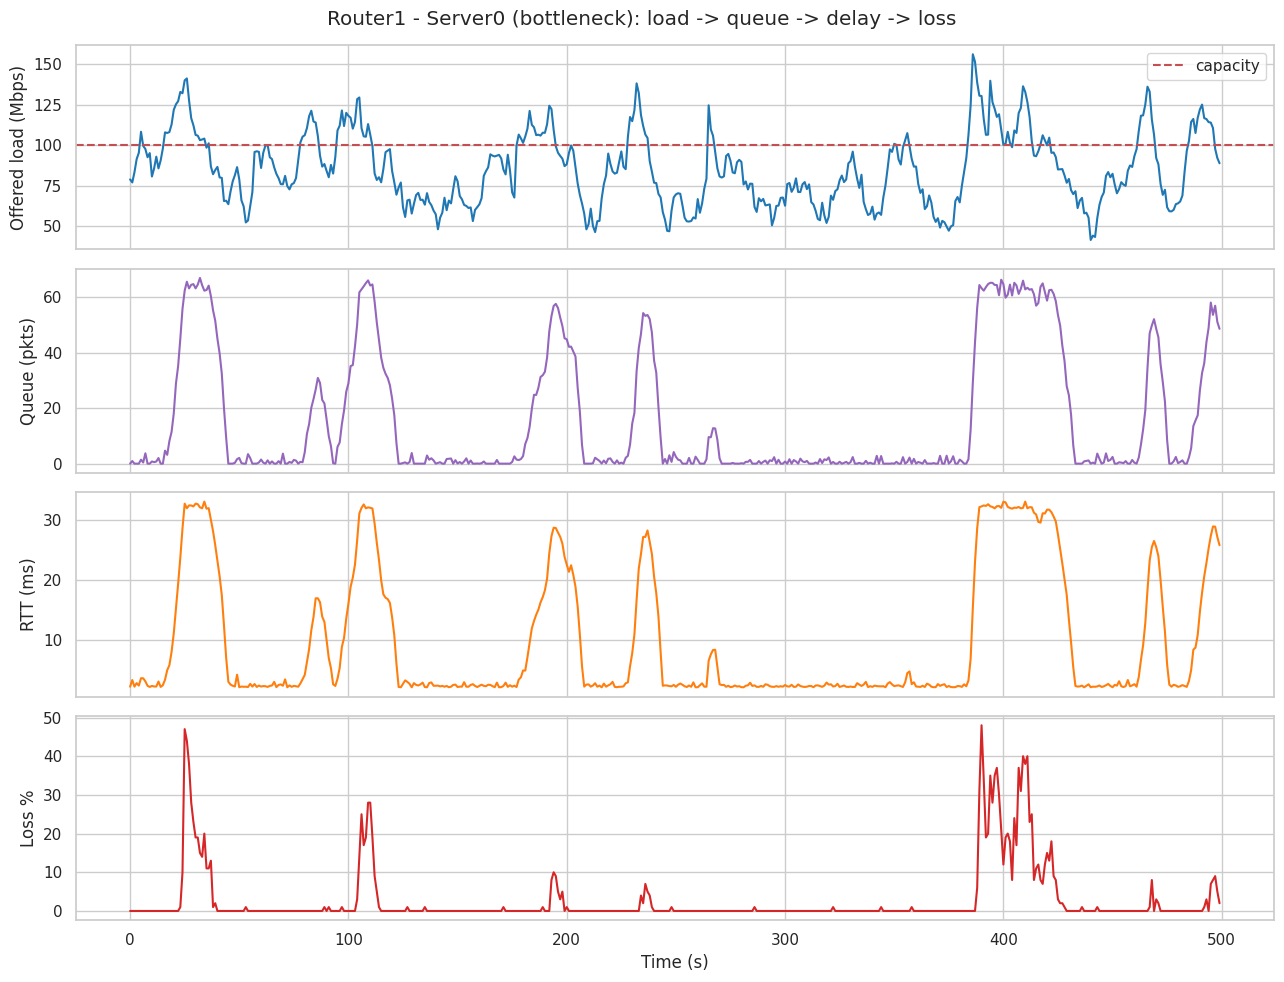

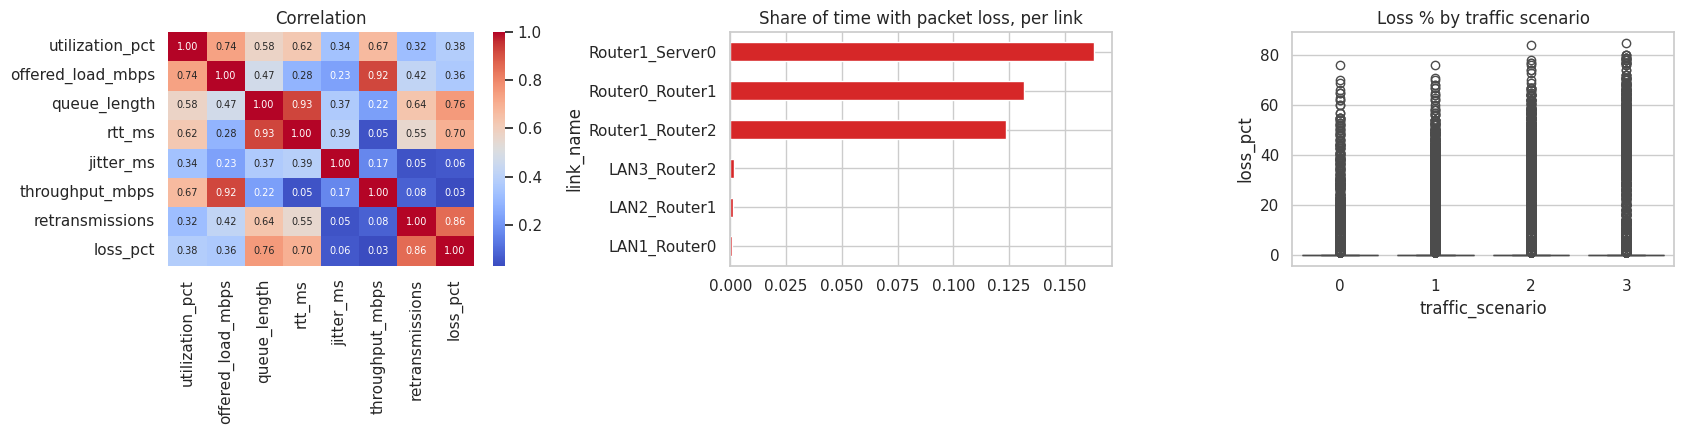

In [4]:
fig, ax = plt.subplots(4, 1, figsize=(13, 10), sharex=True)
sub = df[(df.link_name == 'Router1_Server0') & (df.time < 500)]
ax[0].plot(sub.time, sub.offered_load_mbps, color='tab:blue'); ax[0].axhline(100, color='r', ls='--', label='capacity')
ax[0].set_ylabel('Offered load (Mbps)'); ax[0].legend()
ax[1].plot(sub.time, sub.queue_length, color='tab:purple'); ax[1].set_ylabel('Queue (pkts)')
ax[2].plot(sub.time, sub.rtt_ms, color='tab:orange'); ax[2].set_ylabel('RTT (ms)')
ax[3].plot(sub.time, sub.loss_pct, color='tab:red'); ax[3].set_ylabel('Loss %'); ax[3].set_xlabel('Time (s)')
fig.suptitle('Router1 - Server0 (bottleneck): load -> queue -> delay -> loss'); plt.tight_layout(); plt.show()

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
cols = ['utilization_pct','offered_load_mbps','queue_length','rtt_ms','jitter_ms','throughput_mbps','retransmissions','loss_pct']
sns.heatmap(df[cols].corr(), annot=True, fmt='.2f', cmap='coolwarm', ax=ax[0], annot_kws={'size': 7}); ax[0].set_title('Correlation')
df.groupby('link_name')['current_loss'].mean().sort_values().plot.barh(ax=ax[1], color='tab:red')
ax[1].set_title('Share of time with packet loss, per link')
if 'traffic_scenario' in df:
    sns.boxplot(data=df, x='traffic_scenario', y='loss_pct', ax=ax[2]); ax[2].set_title('Loss % by traffic scenario')
plt.tight_layout(); plt.show()

## 5. Features, targets and time-based split
- **Detection** uses only the *current* snapshot of measurements.
- **Prediction** adds the *recent history* of each link (lags, trends, rolling statistics) and looks `H` seconds ahead.
- Split is **chronological** and the same for every link: first 60% train, next 15% validation (model / threshold choice), last 25% test. Nothing from the future is used for training.
- The hidden `traffic_scenario` column is **not** used as a feature (a real monitor can't see it).

In [13]:
H = 5   # prediction horizon in seconds

BASE = ['capacity_mbps', 'packet_rate_pps', 'packet_size_bytes', 'offered_load_mbps', 'utilization_pct',
        'queue_length', 'rtt_ms', 'jitter_ms', 'throughput_mbps', 'retransmissions']
HIST_BASE = ['utilization_pct', 'queue_length', 'rtt_ms', 'offered_load_mbps', 'loss_pct', 'retransmissions']

def build_history_features(g):
    g = g.sort_values('time').copy()
    for c in HIST_BASE:
        for k in (1, 2, 3, 5): g[f'{c}_lag{k}'] = g[c].shift(k)
    g['util_trend3']  = g['utilization_pct'] - g['utilization_pct'].shift(3)
    g['queue_trend3'] = g['queue_length'] - g['queue_length'].shift(3)
    g['load_trend3']  = g['offered_load_mbps'] - g['offered_load_mbps'].shift(3)
    g['queue_roll5_mean'] = g['queue_length'].rolling(5).mean()
    g['queue_roll5_max']  = g['queue_length'].rolling(5).max()
    g['queue_roll5_std']  = g['queue_length'].rolling(5).std()
    g['load_roll5_mean']  = g['offered_load_mbps'].rolling(5).mean()
    g['util_roll5_max']   = g['utilization_pct'].rolling(5).max()
    g['rtt_roll5_std']    = g['rtt_ms'].rolling(5).std()
    g['loss_roll10_mean'] = g['loss_pct'].rolling(10).mean()
    g['queue_roll10_mean'] = g['queue_length'].rolling(10).mean()
    return g

def add_targets(g, h=H):
    g = g.sort_values('time').copy()

    g['future_loss'] = (
        g['current_loss']
        .shift(-1)
        .rolling(h, min_periods=h)
        .max()
        .shift(-(h - 1))
    )

    g['future_loss_rate'] = (
        g['loss_pct']
        .shift(-1)
        .rolling(h, min_periods=h)
        .mean()
        .shift(-(h - 1))
    )

    return g

probe = build_history_features(df[df.link_name == df.link_name.iloc[0]].head(30))
HIST_COLS = [c for c in probe.columns if c not in df.columns]
DETECT_FEATURES = BASE
PRED_FEATURES = BASE + ['loss_pct'] + HIST_COLS

fe = pd.concat([add_targets(build_history_features(g)) for _, g in df.groupby('link_name')], ignore_index=True)
fe = fe.dropna(subset=PRED_FEATURES + ['future_loss', 'future_loss_rate']).reset_index(drop=True)
fe['future_loss'] = fe['future_loss'].astype(int)

tmax = fe['time'].max()
fe['split'] = np.where(fe['time'] < 0.60*tmax, 'train', np.where(fe['time'] < 0.75*tmax, 'val', 'test'))
tr, va, te = (fe[fe.split == s] for s in ['train', 'val', 'test'])

print('Detection features :', len(DETECT_FEATURES))
print('Prediction features:', len(PRED_FEATURES), '| horizon H =', H, 's')
print(fe['split'].value_counts().to_dict())
print('Future-loss rate  train/val/test: %.3f / %.3f / %.3f' % (tr.future_loss.mean(), va.future_loss.mean(), te.future_loss.mean()))

Detection features : 10
Prediction features: 46 | horizon H = 5 s
{'train': 35928, 'test': 14994, 'val': 8994}
Future-loss rate  train/val/test: 0.088 / 0.123 / 0.099


## 6. Detection - is packet loss happening right now?
Four models are compared; the best one on the **validation** set (ROC-AUC) is selected and then reported on the untouched **test** set.

TEST RESULTS - detection (selected on validation ROC-AUC: Extra Trees)


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.983,0.826,0.981,0.897,0.989
Random Forest,0.995,0.961,0.973,0.967,0.990
Extra Trees,0.994,0.937,0.979,0.958,0.990
Gradient Boosting,0.995,0.973,0.965,0.969,0.989


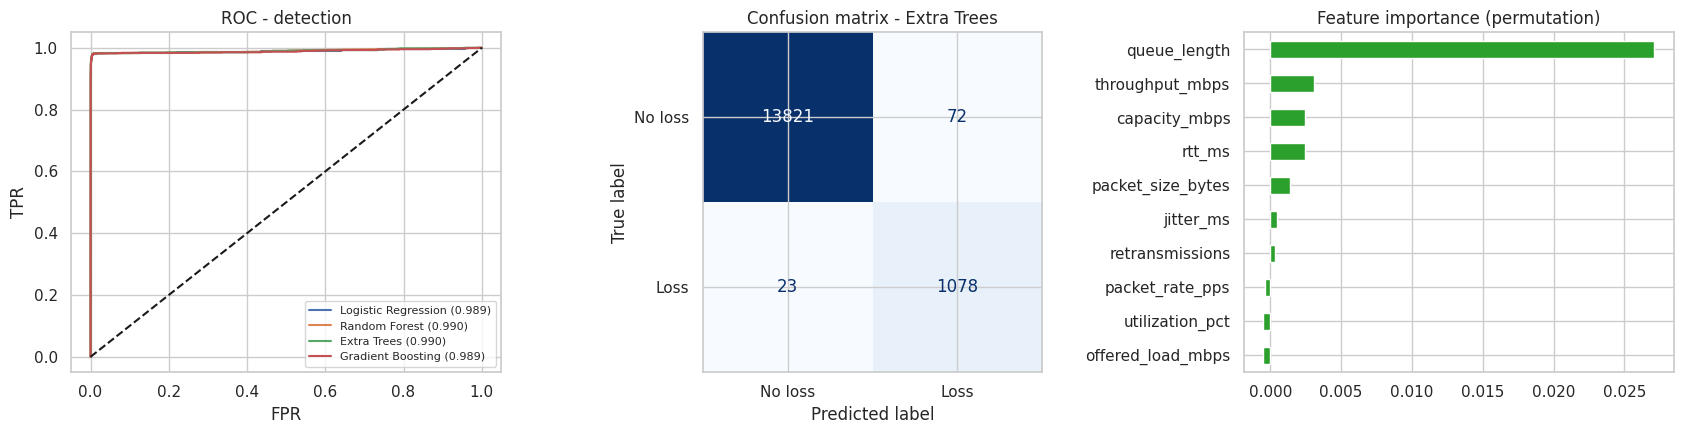

In [14]:
def clf_metrics(y, proba, thr=0.5):
    pred = (proba >= thr).astype(int)
    return {'Accuracy': accuracy_score(y, pred), 'Precision': precision_score(y, pred, zero_division=0),
            'Recall': recall_score(y, pred, zero_division=0), 'F1': f1_score(y, pred, zero_division=0),
            'ROC-AUC': roc_auc_score(y, proba)}

def perm_importance_plot(model, X, y, ax, title, top=10):
    idx = np.random.default_rng(0).choice(len(X), min(3000, len(X)), replace=False)
    r = permutation_importance(model, X.iloc[idx], y.iloc[idx], scoring='roc_auc', n_repeats=3, random_state=0, n_jobs=-1)
    pd.Series(r.importances_mean, index=X.columns).sort_values().tail(top).plot.barh(ax=ax, color='tab:green')
    ax.set_title(title)

det_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=2000, class_weight='balanced')),
    'Random Forest': RandomForestClassifier(n_estimators=120, max_depth=16, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=120, max_depth=16, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=SEED),
}
det_rows, det_val_auc, det_test_proba = [], {}, {}
for name, m in det_models.items():
    m.fit(tr[DETECT_FEATURES], tr['current_loss'])
    det_val_auc[name] = roc_auc_score(va['current_loss'], m.predict_proba(va[DETECT_FEATURES])[:, 1])
    det_test_proba[name] = m.predict_proba(te[DETECT_FEATURES])[:, 1]
    det_rows.append({'Model': name, **clf_metrics(te['current_loss'], det_test_proba[name])})

det_table = pd.DataFrame(det_rows).set_index('Model').round(3)
best_det_name = max(det_val_auc, key=det_val_auc.get)
detection_model = det_models[best_det_name]
print('TEST RESULTS - detection (selected on validation ROC-AUC: %s)' % best_det_name)
display(det_table)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
for name, pr in det_test_proba.items():
    fpr, tpr, _ = roc_curve(te['current_loss'], pr); ax[0].plot(fpr, tpr, label='%s (%.3f)' % (name, det_table.loc[name, 'ROC-AUC']))
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_title('ROC - detection'); ax[0].set_xlabel('FPR'); ax[0].set_ylabel('TPR'); ax[0].legend(fontsize=8)
ConfusionMatrixDisplay(confusion_matrix(te['current_loss'], (det_test_proba[best_det_name] >= 0.5).astype(int)),
                       display_labels=['No loss', 'Loss']).plot(ax=ax[1], cmap='Blues', colorbar=False)
ax[1].set_title('Confusion matrix - ' + best_det_name)
perm_importance_plot(detection_model, te[DETECT_FEATURES], te['current_loss'], ax[2], 'Feature importance (permutation)')
plt.tight_layout(); plt.show()

## 7. Prediction - will packet loss occur in the next H seconds?
This is the early-warning model. It uses the history features, and the alert threshold is **tuned on the validation set** (best F1), not on the test set. The "persistence" baseline simply assumes *loss in H seconds = loss now*; a useful model must beat it.

TEST RESULTS - 5-second-ahead loss prediction (selected on validation ROC-AUC: Gradient Boosting, threshold 0.36)


,Accuracy,Precision,Recall,F1,ROC-AUC
Model,,,,,
Logistic Regression,0.972,0.881,0.826,0.853,0.957
Random Forest,0.970,0.860,0.836,0.848,0.951
Extra Trees,0.972,0.895,0.812,0.852,0.954
Gradient Boosting,0.970,0.859,0.831,0.845,0.954
Persistence baseline,0.962,0.916,0.680,0.781,NaN


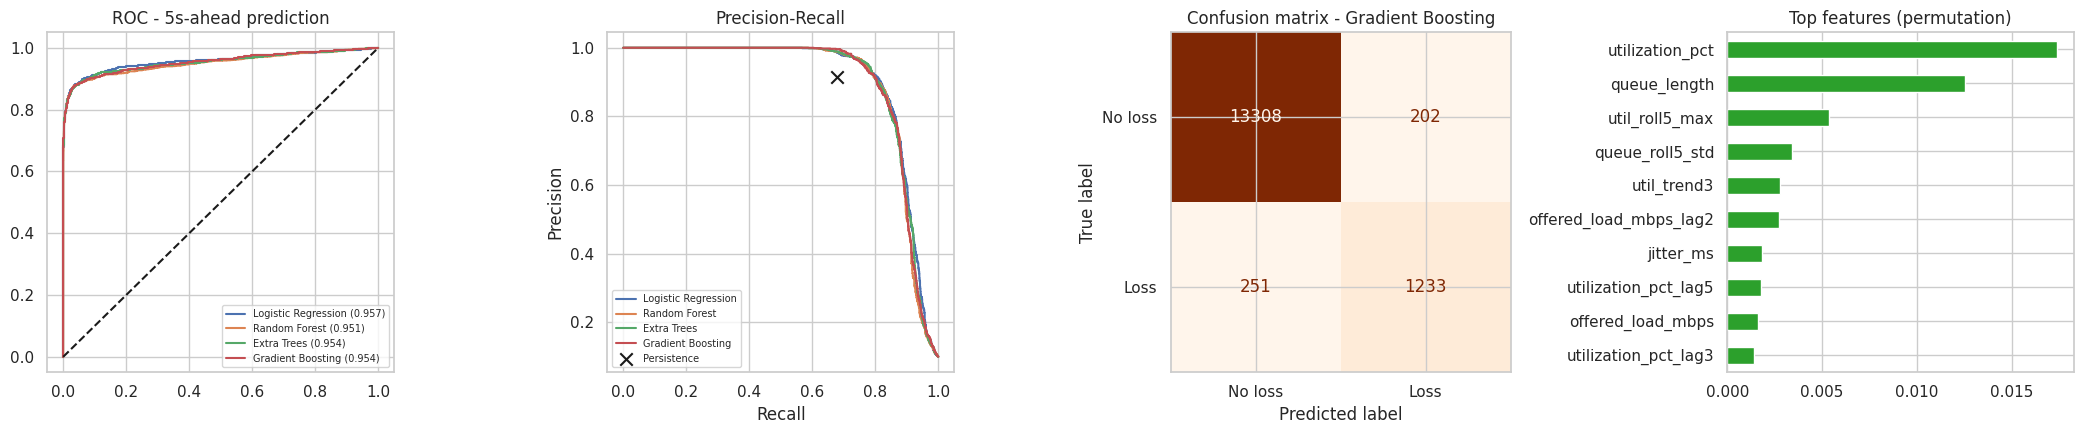

In [15]:
pred_models = {
    'Logistic Regression': make_pipeline(StandardScaler(), LogisticRegression(max_iter=3000, class_weight='balanced')),
    'Random Forest': RandomForestClassifier(n_estimators=120, max_depth=16, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Extra Trees': ExtraTreesClassifier(n_estimators=120, max_depth=16, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingClassifier(random_state=SEED),
}
def best_threshold(y, proba):
    prec, rec, thr = precision_recall_curve(y, proba)
    f1s = 2*prec*rec/(prec + rec + 1e-9)
    return float(thr[np.argmax(f1s[:-1])])

pred_rows, pred_val_auc, pred_test_proba, pred_thr = [], {}, {}, {}
for name, m in pred_models.items():
    m.fit(tr[PRED_FEATURES], tr['future_loss'])
    pv = m.predict_proba(va[PRED_FEATURES])[:, 1]
    pred_val_auc[name] = roc_auc_score(va['future_loss'], pv)
    pred_thr[name] = best_threshold(va['future_loss'], pv)
    pred_test_proba[name] = m.predict_proba(te[PRED_FEATURES])[:, 1]
    pred_rows.append({'Model': name, **clf_metrics(te['future_loss'], pred_test_proba[name], pred_thr[name])})

base_pred = te['current_loss'].values
pred_rows.append({'Model': 'Persistence baseline', 'Accuracy': accuracy_score(te['future_loss'], base_pred),
                  'Precision': precision_score(te['future_loss'], base_pred, zero_division=0),
                  'Recall': recall_score(te['future_loss'], base_pred, zero_division=0),
                  'F1': f1_score(te['future_loss'], base_pred, zero_division=0), 'ROC-AUC': np.nan})
pred_table = pd.DataFrame(pred_rows).set_index('Model').round(3)
best_pred_name = max(pred_val_auc, key=pred_val_auc.get)
prediction_model, PRED_THR = pred_models[best_pred_name], pred_thr[best_pred_name]
print('TEST RESULTS - %d-second-ahead loss prediction (selected on validation ROC-AUC: %s, threshold %.2f)' % (H, best_pred_name, PRED_THR))
display(pred_table)

fig, ax = plt.subplots(1, 4, figsize=(21, 4.5))
for name, pr in pred_test_proba.items():
    fpr, tpr, _ = roc_curve(te['future_loss'], pr); ax[0].plot(fpr, tpr, label='%s (%.3f)' % (name, pred_table.loc[name, 'ROC-AUC']))
ax[0].plot([0, 1], [0, 1], 'k--'); ax[0].set_title('ROC - %ds-ahead prediction' % H); ax[0].legend(fontsize=7)
for name, pr in pred_test_proba.items():
    p_, r_, _ = precision_recall_curve(te['future_loss'], pr); ax[1].plot(r_, p_, label=name)
ax[1].scatter([pred_table.loc['Persistence baseline', 'Recall']], [pred_table.loc['Persistence baseline', 'Precision']],
              color='k', marker='x', s=80, label='Persistence'); ax[1].set_title('Precision-Recall'); ax[1].set_xlabel('Recall'); ax[1].set_ylabel('Precision'); ax[1].legend(fontsize=7)
ConfusionMatrixDisplay(confusion_matrix(te['future_loss'], (pred_test_proba[best_pred_name] >= PRED_THR).astype(int)),
                       display_labels=['No loss', 'Loss']).plot(ax=ax[2], cmap='Oranges', colorbar=False)
ax[2].set_title('Confusion matrix - ' + best_pred_name)
perm_importance_plot(prediction_model, te[PRED_FEATURES], te['future_loss'], ax[3], 'Top features (permutation)')
plt.tight_layout(); plt.show()

## 8. Regression - how much packet loss in the next H seconds?

TEST RESULTS - loss-rate forecast (5 s ahead), selected on validation MAE: Gradient Boosting


,MAE,RMSE,R2
Model,,,
Random Forest,1.101,4.012,0.774
Gradient Boosting,1.090,4.039,0.771
Persistence baseline,1.426,5.671,0.549


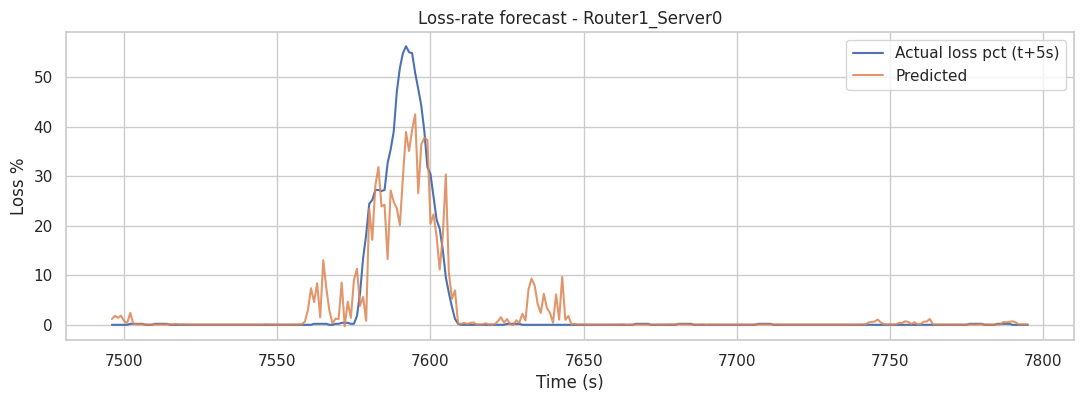

In [16]:
reg_models = {
    'Random Forest': RandomForestRegressor(n_estimators=120, max_depth=16, min_samples_leaf=3, random_state=SEED, n_jobs=-1),
    'Gradient Boosting': HistGradientBoostingRegressor(random_state=SEED),
}
def reg_metrics(y, p):
    return {'MAE': mean_absolute_error(y, p), 'RMSE': mean_squared_error(y, p)**0.5, 'R2': r2_score(y, p)}

reg_rows, reg_val_mae = [], {}
for name, m in reg_models.items():
    m.fit(tr[PRED_FEATURES], tr['future_loss_rate'])
    reg_val_mae[name] = mean_absolute_error(va['future_loss_rate'], m.predict(va[PRED_FEATURES]))
    reg_rows.append({'Model': name, **reg_metrics(te['future_loss_rate'], m.predict(te[PRED_FEATURES]))})
reg_rows.append({'Model': 'Persistence baseline', **reg_metrics(te['future_loss_rate'], te['loss_pct'])})
reg_table = pd.DataFrame(reg_rows).set_index('Model').round(3)
best_reg_name = min(reg_val_mae, key=reg_val_mae.get)
regression_model = reg_models[best_reg_name]
print('TEST RESULTS - loss-rate forecast (%d s ahead), selected on validation MAE: %s' % (H, best_reg_name))
display(reg_table)

s_ = te[te.link_name == 'Router1_Server0'].sort_values('time').iloc[:300]
plt.figure(figsize=(13, 4))
plt.plot(s_['time'], s_['future_loss_rate'], label='Actual loss pct (t+%ds)' % H)
plt.plot(s_['time'], regression_model.predict(s_[PRED_FEATURES]), label='Predicted', alpha=.85)
plt.xlabel('Time (s)'); plt.ylabel('Loss %'); plt.title('Loss-rate forecast - Router1_Server0'); plt.legend(); plt.show()

## 9. Does it generalise to links it has never seen?
For each link: train on the **other five links** (training period only) and test on the held-out link's **test period**. Links that almost never lose packets (LAN links) can't give an AUC, which is shown as NaN.

In [17]:
rows = []
for link in LINKS:
    a = fe[(fe.link_name != link) & (fe.split == 'train')]
    b = fe[(fe.link_name == link) & (fe.split == 'test')]
    m = RandomForestClassifier(n_estimators=100, min_samples_leaf=3, class_weight='balanced', random_state=SEED, n_jobs=-1)
    m.fit(a[PRED_FEATURES], a['future_loss'])
    pr = m.predict_proba(b[PRED_FEATURES])[:, 1]
    ok = b['future_loss'].nunique() == 2
    rows.append({'Held-out link': link, 'Loss rate in test': round(b['future_loss'].mean(), 3),
                 'ROC-AUC': round(roc_auc_score(b['future_loss'], pr), 3) if ok else np.nan,
                 'F1': round(f1_score(b['future_loss'], (pr >= 0.5).astype(int), zero_division=0), 3)})
unseen_table = pd.DataFrame(rows).set_index('Held-out link'); display(unseen_table)

,Loss rate in test,ROC-AUC,F1
Held-out link,,,
LAN1_Router0,0.004,0.362,0.000
LAN2_Router1,0.007,0.527,0.000
LAN3_Router2,0.004,0.460,0.000
Router0_Router1,0.220,0.957,0.869
Router1_Router2,0.174,0.940,0.851
Router1_Server0,0.185,0.937,0.860


## 10. Early-warning quality
Metrics that matter for an alert system:
- **Episodes warned** - share of new loss episodes preceded by at least one alert in the previous 10 s
- **Lead time** - how many seconds before the loss the first alert fired
- **False alarms** - alerts not followed by any loss within the next H+2 seconds

Loss episodes in test set : 99
Episodes warned in advance: 81.8%
Median lead time          : 4.0 s
Alerts raised             : 1435 | false alarms: 11.4%


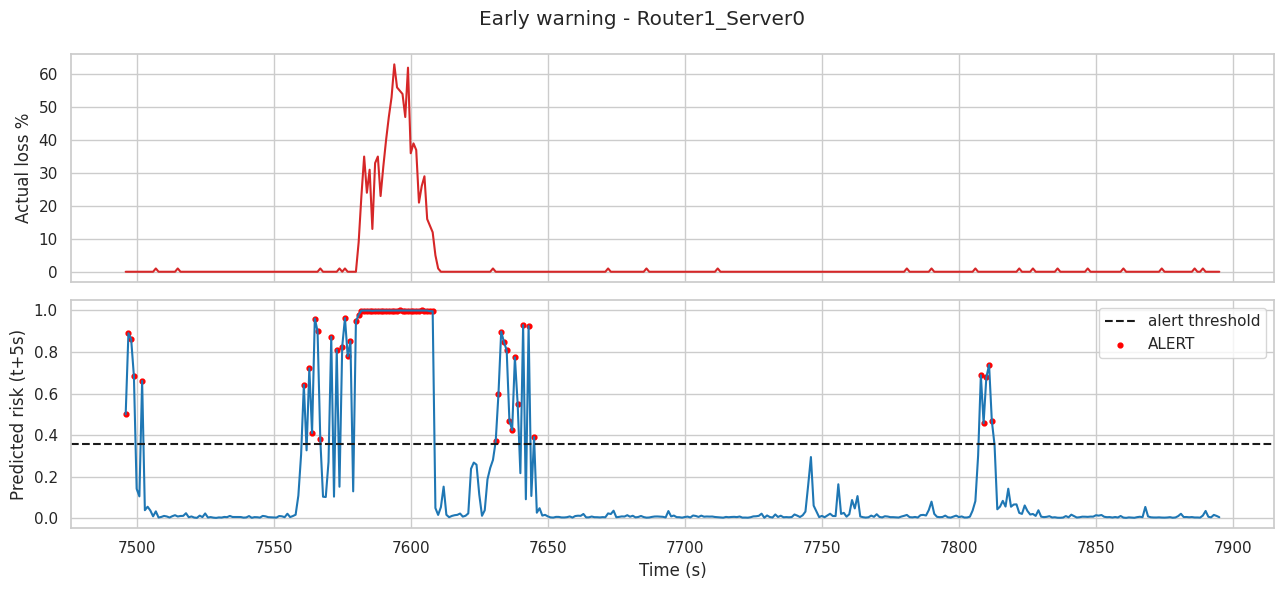

In [18]:
test_ev = te.copy()
test_ev['risk'] = prediction_model.predict_proba(test_ev[PRED_FEATURES])[:, 1]
test_ev['alert'] = (test_ev['risk'] >= PRED_THR).astype(int)

warned, leads, false_alarms, total_alerts, episodes = [], [], 0, 0, 0
for link, g in test_ev.groupby('link_name'):
    g = g.sort_values('time').reset_index(drop=True)
    cur, al = g['current_loss'].values, g['alert'].values
    for e in np.where((cur == 1) & (np.r_[0, cur[:-1]] == 0))[0]:
        lo = max(0, e - 10); w = al[lo:e]
        if len(w) == 0: continue
        hit = np.where(w == 1)[0]; warned.append(len(hit) > 0)
        if len(hit): leads.append(e - (lo + hit[0]))
    for i in np.where(al == 1)[0]:
        total_alerts += 1
        if cur[i:i + H + 3].max() == 0: false_alarms += 1

print('Loss episodes in test set : %d' % len(warned))
print('Episodes warned in advance: %.1f%%' % (100*np.mean(warned)))
print('Median lead time          : %.1f s' % (np.median(leads) if leads else float('nan')))
print('Alerts raised             : %d | false alarms: %.1f%%' % (total_alerts, 100*false_alarms/max(total_alerts, 1)))

g = test_ev[test_ev.link_name == 'Router1_Server0'].sort_values('time').iloc[:400]
fig, ax = plt.subplots(2, 1, figsize=(13, 6), sharex=True)
ax[0].plot(g['time'], g['loss_pct'], color='tab:red'); ax[0].set_ylabel('Actual loss %')
ax[1].plot(g['time'], g['risk'], color='tab:blue'); ax[1].axhline(PRED_THR, color='k', ls='--', label='alert threshold')
a_ = g[g.alert == 1]; ax[1].scatter(a_['time'], a_['risk'], color='red', s=12, label='ALERT')
ax[1].set_ylabel('Predicted risk (t+%ds)' % H); ax[1].set_xlabel('Time (s)'); ax[1].legend()
plt.suptitle('Early warning - Router1_Server0'); plt.tight_layout(); plt.show()

## 11. Inference demo - `analyze_link()`

In [20]:
def analyze_link(history):
    h = history.copy()
    if 'current_loss' not in h: h['current_loss'] = (h['loss_pct'] >= LOSS_THRESHOLD_PCT).astype(int)
    f = build_history_features(h).iloc[[-1]]
    if f[PRED_FEATURES].isna().values.any():
        raise ValueError('Need at least 11 consecutive seconds of measurements for this link')
    cur_p = float(detection_model.predict_proba(f[DETECT_FEATURES])[0, 1])
    fut_p = float(prediction_model.predict_proba(f[PRED_FEATURES])[0, 1])
    rate = float(max(0, regression_model.predict(f[PRED_FEATURES])[0]))
    print('=' * 58); print('AI NETWORK ANALYSIS -', h['link_name'].iloc[-1], '| t =', int(h['time'].iloc[-1]), 's'); print('=' * 58)
    print('Current packet loss : %-13s (probability %.1f%%)' % ('DETECTED' if cur_p >= 0.5 else 'NOT DETECTED', cur_p*100))
    print('Loss in next %ds    : %-13s (risk %.1f%%, alert threshold %.0f%%)' % (H, 'WARNING' if fut_p >= PRED_THR else 'OK', fut_p*100, PRED_THR*100))
    print('Expected loss rate  : %.2f%% in %d s' % (rate, H)); print('=' * 58)

def get_history(link, t, n=12):
    return df[(df.link_name == link) & (df.time > t - n) & (df.time <= t)]

cand = te[te.link_name == 'Router1_Server0']
calm = cand[(cand.current_loss == 0) & (cand.future_loss == 0) & (cand.utilization_pct < 50)]
pre = cand[(cand.current_loss == 0) & (cand.future_loss == 1)]
print('CASE 1 - NORMAL NETWORK'); analyze_link(get_history('Router1_Server0', int(calm.iloc[len(calm)//2]['time'])))
print('\nCASE 2 - JUST BEFORE CONGESTION'); analyze_link(get_history('Router1_Server0', int(pre.iloc[len(pre)//2]['time'])))

CASE 1 - NORMAL NETWORK
AI NETWORK ANALYSIS - Router1_Server0 | t = 8702 s
Current packet loss : NOT DETECTED  (probability 2.0%)
Loss in next 5s    : OK            (risk 0.8%, alert threshold 36%)
Expected loss rate  : 0.06% in 5 s

CASE 2 - JUST BEFORE CONGESTION
AI NETWORK ANALYSIS - Router1_Server0 | t = 8822 s
Current packet loss : NOT DETECTED  (probability 1.3%)
Loss in next 5s    : WARNING       (risk 37.1%, alert threshold 36%)
Expected loss rate  : 3.18% in 5 s


## 12. Save models, results and download everything

In [21]:
joblib.dump(detection_model, f'{OUTPUT_DIR}/detection_model.pkl')
joblib.dump(prediction_model, f'{OUTPUT_DIR}/prediction_model.pkl')
joblib.dump(regression_model, f'{OUTPUT_DIR}/regression_model.pkl')
det_table.to_csv(f'{OUTPUT_DIR}/detection_results.csv'); pred_table.to_csv(f'{OUTPUT_DIR}/prediction_results.csv')
reg_table.to_csv(f'{OUTPUT_DIR}/regression_results.csv'); unseen_table.to_csv(f'{OUTPUT_DIR}/unseen_link_results.csv')
df.to_csv(f'{OUTPUT_DIR}/network_dataset.csv', index=False)

config = {'horizon_seconds': H, 'loss_threshold_pct': LOSS_THRESHOLD_PCT, 'alert_threshold': PRED_THR,
          'detection_model': best_det_name, 'prediction_model': best_pred_name, 'regression_model': best_reg_name,
          'detect_features': DETECT_FEATURES, 'prediction_features': PRED_FEATURES,
          'episodes_warned_pct': float(100*np.mean(warned)) if warned else None,
          'median_lead_time_s': float(np.median(leads)) if leads else None}
with open(f'{OUTPUT_DIR}/config.json', 'w') as f: json.dump(config, f, indent=2)
print('Saved:', sorted(os.listdir(OUTPUT_DIR)))

zip_path = shutil.make_archive('AI_Packet_Loss_Project', 'zip', OUTPUT_DIR)
try:
    from google.colab import files
    files.download(zip_path)
except Exception:
    print('ZIP created at', zip_path)

Saved: ['config.json', 'detection_model.pkl', 'detection_results.csv', 'network_dataset.csv', 'prediction_model.pkl', 'prediction_results.csv', 'regression_model.pkl', 'regression_results.csv', 'unseen_link_results.csv']


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Conclusion
- Packet loss on this network is driven by **congestion on the shared Router1 - Server0 link**: offered load rises, the queue fills, RTT grows, then packets drop.
- The **detector** recognises loss from the current snapshot; the **predictor** uses recent history to raise an alert seconds *before* loss, and is compared with a naive persistence baseline.
- The **regression** model forecasts how large the loss will be.
- The evaluation uses a chronological split, validation-based model/threshold selection, a leave-one-link-out test and alert-level metrics (episodes warned, lead time, false alarms).
- **Limitations:** the data is simulated; with real Packet Tracer measurements (Option B) numbers will differ. **Future work:** LSTM/GRU models, real SNMP/NetFlow telemetry, and automatic QoS or rerouting triggered by alerts.